# 01 · Data Understanding

**Purpose:** inspect the original `Tweets.csv` exactly as provided, before any cleaning, and list every quality issue the cleaning step must handle.

**Questions answered**
- What does one record look like, and which columns are usable?
- How complete is the data, and are missing values errors or structural?
- Are there duplicate records or conflicting labels?
- Can the `airline` label be trusted?

> This notebook is read-only. It never modifies the raw file; all cleaning happens in `02_data_cleaning.ipynb`.

## 1. Project Objective

Airlines receive a constant stream of public feedback on social media. This project turns a labelled set of airline tweets into business-ready insight:

- How do customers feel about each airline?
- Which complaint categories dominate, and do they differ by airline?
- Which tweets get amplified (retweeted)?
- How does sentiment change across the collection window?

The source file already contains a human-assigned sentiment label for every tweet (`positive`, `neutral`, `negative`). The project therefore analyses these **existing labels**. The descriptive analysis (notebooks 03–05) uses these labels directly. Notebooks 06–10 train text models to predict them; model predictions never replace the labels.

Before any analysis, we need to understand the data's structure, completeness and quality issues. That is the purpose of this notebook.

## 2. Setup

- **pandas** – loading and inspection
- **matplotlib** – quick visual checks
- `src.preprocessing.mask_user_handles` – tweets shown in this notebook have non-airline `@usernames` replaced by `@user`; the raw file itself is not changed.

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable from any folder inside the repository
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import RAW_DATA_PATH
from src.data import load_raw_tweets
from src.plotting import PRIMARY_COLOR, SENTIMENT_COLORS, apply_style
from src.preprocessing import mask_user_handles

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
apply_style()


def for_display(frame):
    """Hide usernames in tables shown in the notebook (the data itself is unchanged)."""
    frame = frame.drop(columns=["name"], errors="ignore")
    return frame.assign(text=frame["text"].map(mask_user_handles)) if "text" in frame else frame

## 3. Load Raw Dataset

The raw file is expected at `data/raw/Tweets.csv` (see the README for how to download it).

In [2]:
# Load the original file exactly as provided (no parsing options that change values)
df = load_raw_tweets()

print(f"Raw dataset loaded from: {RAW_DATA_PATH.relative_to(PROJECT_ROOT).as_posix()}")

Raw dataset loaded from: data/raw/Tweets.csv


## 4. Preview Dataset

The first five rows show what a single record looks like. The `name` column (the poster's Twitter username) is hidden from the preview; it is dropped during cleaning.

In [3]:
for_display(df.head())

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,NaN,0,@VirginAmerica What @user said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,NaN,0,@VirginAmerica plus you've added commercials to the experience... tacky.,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,NaN,0,@VirginAmerica I didn't today... Must mean I need to take another trip!,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,NaN,0,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have littl...",NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,NaN,0,@VirginAmerica and it's a really big bad thing about it,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


## 5. Dataset Dimensions

In [4]:
# df.shape returns a (rows, columns) tuple
row_count, column_count = df.shape

print(f"Number of rows (tweets): {row_count:,}")
print(f"Number of columns: {column_count}")

Number of rows (tweets): 14,640
Number of columns: 15


## 6. Column Names

A numbered list of every column in the raw file.

In [5]:
for column_number, column_name in enumerate(df.columns, start=1):
    print(f"{column_number:>2}. {column_name}")

 1. tweet_id
 2. airline_sentiment
 3. airline_sentiment_confidence
 4. negativereason
 5. negativereason_confidence
 6. airline
 7. airline_sentiment_gold
 8. name
 9. negativereason_gold
10. retweet_count
11. text
12. tweet_coord
13. tweet_created
14. tweet_location
15. user_timezone


## 7. Dataset Information

`df.info()` shows each column's data type and non-null count. It also shows that `tweet_created` is stored as text (`object`) and `tweet_id` as a large integer. Both types are corrected during cleaning.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  str    
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   str    
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  str    
 6   airline_sentiment_gold        40 non-null     str    
 7   name                          14640 non-null  str    
 8   negativereason_gold           32 non-null     str    
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  str    
 11  tweet_coord                   1019 non-null   str    
 12  tweet_created                 14640 non-null  str    
 13  tweet_locati

## 8. Missing Value Analysis

Missing values are summarised as counts and percentages and sorted from most to least missing.

In [7]:
# Count and percentage of missing values per column
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
}).sort_values("missing_percentage", ascending=False)

missing_summary

,missing_count,missing_percentage
negativereason_gold,14608,99.78
airline_sentiment_gold,14600,99.73
tweet_coord,13621,93.04
negativereason,5462,37.31
user_timezone,4820,32.92
tweet_location,4733,32.33
negativereason_confidence,4118,28.13
airline,0,0.00
tweet_id,0,0.00
airline_sentiment,0,0.00


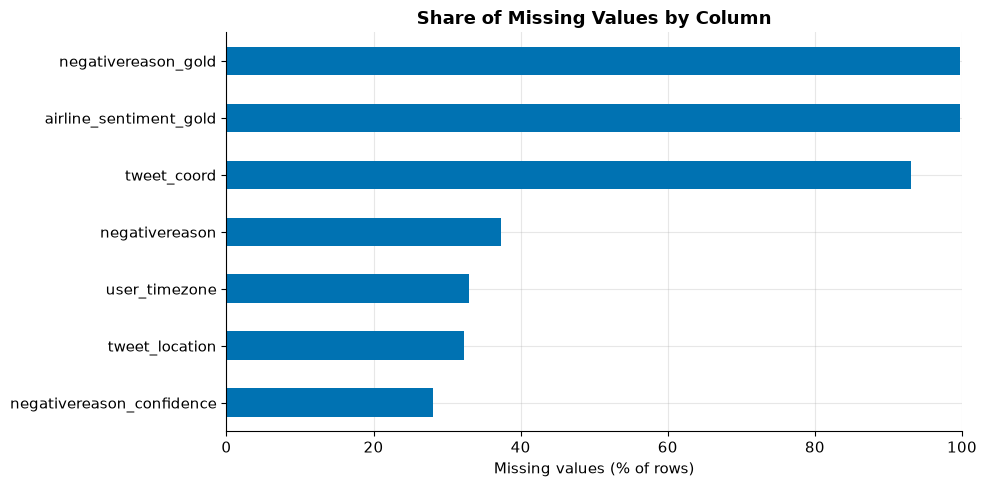

Columns with at least one missing value: 7 of 15


In [8]:
# Visualise only the columns that actually contain missing values
columns_with_missing = missing_summary[missing_summary["missing_count"] > 0]

ax = columns_with_missing["missing_percentage"].sort_values().plot(kind="barh", color=PRIMARY_COLOR)
ax.set_title("Share of Missing Values by Column")
ax.set_xlabel("Missing values (% of rows)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

print(f"Columns with at least one missing value: {len(columns_with_missing)} of {column_count}")

**What the missing values mean:**

- `airline_sentiment_gold`, `negativereason_gold` and `tweet_coord` are almost entirely empty, so they add little analytical value.
- `negativereason` and `negativereason_confidence` are **structurally** missing: a complaint reason only exists when a tweet is negative. The next cell checks this.
- `tweet_location` and `user_timezone` are optional profile fields that many users leave blank.

In [9]:
# Is negativereason missing only for non-negative tweets?
negative_mask = df["airline_sentiment"] == "negative"

negative_without_reason = df.loc[negative_mask, "negativereason"].isna().sum()
non_negative_with_reason = df.loc[~negative_mask, "negativereason"].notna().sum()

print(f"Negative tweets WITHOUT a negative reason: {negative_without_reason:,}")
print(f"Non-negative tweets WITH a negative reason: {non_negative_with_reason:,}")
print(f"Non-negative tweets with negativereason_confidence missing: "
      f"{df.loc[~negative_mask, 'negativereason_confidence'].isna().sum():,}")
print(f"Non-negative tweets with negativereason_confidence = 0: "
      f"{(df.loc[~negative_mask, 'negativereason_confidence'] == 0).sum():,}")

Negative tweets WITHOUT a negative reason: 0
Non-negative tweets WITH a negative reason: 0
Non-negative tweets with negativereason_confidence missing: 4,118
Non-negative tweets with negativereason_confidence = 0: 1,344


## 9. Exact Duplicate Analysis

An exact duplicate is a row where **every** column matches another row.

In [10]:
# duplicated() flags the 2nd, 3rd... copies of a row (the first copy is not flagged)
exact_duplicate_count = df.duplicated().sum()

# keep=False flags every copy so all involved records can be inspected
exact_duplicate_records = df[df.duplicated(keep=False)].sort_values("tweet_id")

print(f"Exact duplicate rows (extra copies): {exact_duplicate_count:,}")
print(f"Rows involved in exact duplication: {len(exact_duplicate_records):,}")
print(f"Airlines involved: {exact_duplicate_records['airline'].unique().tolist()}")

for_display(exact_duplicate_records.head(10))

Exact duplicate rows (extra copies): 36
Rows involved in exact duplication: 72
Airlines involved: ['American']


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
12001,570272018840428544,neutral,1.0,NaN,NaN,American,NaN,NaN,0,@AmericanAir I thought all those planes were retired? #MD80,NaN,2015-02-24 09:20:19 -0800,United States,Mountain Time (US & Canada)
12162,570272018840428544,neutral,1.0,NaN,NaN,American,NaN,NaN,0,@AmericanAir I thought all those planes were retired? #MD80,NaN,2015-02-24 09:20:19 -0800,United States,Mountain Time (US & Canada)
12159,570272880556011520,positive,1.0,NaN,NaN,American,NaN,NaN,0,"@americanair new plane, #gogo, easy power for laptop, iPhone, just missing a good boat-style swivel cup holder for m...","[0.0, 0.0]",2015-02-24 09:23:44 -0800,"alexandria, va",Eastern Time (US & Canada)
11998,570272880556011520,positive,1.0,NaN,NaN,American,NaN,NaN,0,"@americanair new plane, #gogo, easy power for laptop, iPhone, just missing a good boat-style swivel cup holder for m...","[0.0, 0.0]",2015-02-24 09:23:44 -0800,"alexandria, va",Eastern Time (US & Canada)
11997,570273710210469888,positive,1.0,NaN,NaN,American,NaN,NaN,0,@AmericanAir These are some awesome photos. Thanks for sharing! 😁,NaN,2015-02-24 09:27:02 -0800,Virginia,Eastern Time (US & Canada)
12158,570273710210469888,positive,1.0,NaN,NaN,American,NaN,NaN,0,@AmericanAir These are some awesome photos. Thanks for sharing! 😁,NaN,2015-02-24 09:27:02 -0800,Virginia,Eastern Time (US & Canada)
12157,570273819287531520,positive,1.0,NaN,NaN,American,NaN,NaN,0,@AmericanAir Aww Thanks AA..DFW was on GMA up here this AM..so i understand ..Btw A.A is my Airline when im able to ...,NaN,2015-02-24 09:27:28 -0800,East Coast CT.,Central Time (US & Canada)
11996,570273819287531520,positive,1.0,NaN,NaN,American,NaN,NaN,0,@AmericanAir Aww Thanks AA..DFW was on GMA up here this AM..so i understand ..Btw A.A is my Airline when im able to ...,NaN,2015-02-24 09:27:28 -0800,East Coast CT.,Central Time (US & Canada)
11994,570275010759102466,negative,1.0,Lost Luggage,1.0,American,NaN,NaN,0,@AmericanAir this delayed bag was for my friend Lisa Pafe. She got her bag after 3 days in Costa Rica. Issue no upda...,NaN,2015-02-24 09:32:12 -0800,NaN,NaN
12155,570275010759102466,negative,1.0,Lost Luggage,1.0,American,NaN,NaN,0,@AmericanAir this delayed bag was for my friend Lisa Pafe. She got her bag after 3 days in Costa Rica. Issue no upda...,NaN,2015-02-24 09:32:12 -0800,NaN,NaN


## 10. Duplicate Tweet ID Analysis

`tweet_id` should uniquely identify a tweet. Some IDs appear more than once, and the repeated rows are **not always identical**.

In [11]:
duplicate_id_mask = df.duplicated(subset="tweet_id", keep=False)
duplicate_id_records = df.loc[duplicate_id_mask].sort_values("tweet_id")

print(f"Extra rows sharing an existing tweet_id: {df.duplicated(subset='tweet_id').sum():,}")
print(f"Rows involved in duplicate tweet IDs: {duplicate_id_mask.sum():,}")
print(f"Distinct tweet IDs that are repeated: {duplicate_id_records['tweet_id'].nunique():,}")

for_display(duplicate_id_records[[
    "tweet_id", "airline", "airline_sentiment", "airline_sentiment_confidence",
    "negativereason", "negativereason_confidence", "text",
]].head(12))

Extra rows sharing an existing tweet_id: 155
Rows involved in duplicate tweet IDs: 310
Distinct tweet IDs that are repeated: 155


,tweet_id,airline,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,text
14556,569600137296633856,American,positive,1.0000,NaN,NaN,@AmericanAir Thank you.....you do the same!!
12033,569600137296633856,American,positive,0.9236,NaN,0.0000,@AmericanAir Thank you.....you do the same!!
12032,569601363799359488,American,negative,0.9553,Flight Attendant Complaints,0.9553,@AmericanAir should reconsider #usairways acquisition. Flight 1843 AA gold flyers insulted by attendant for hanging ...
14543,569601363799359488,American,negative,1.0000,Flight Attendant Complaints,1.0000,@AmericanAir should reconsider #usairways acquisition. Flight 1843 AA gold flyers insulted by attendant for hanging ...
14392,569621879633391616,American,negative,1.0000,Customer Service Issue,1.0000,@AmericanAir no response to DM or email yet. customer service?
12031,569621879633391616,American,negative,1.0000,Customer Service Issue,1.0000,@AmericanAir no response to DM or email yet. customer service?
12030,569622568459636736,American,negative,1.0000,Customer Service Issue,1.0000,@AmericanAir I want to speak to a human being! !! This is not an obscene request!
14386,569622568459636736,American,negative,1.0000,Customer Service Issue,0.6398,@AmericanAir I want to speak to a human being! !! This is not an obscene request!
13995,569680231012773888,American,negative,1.0000,Customer Service Issue,1.0000,@AmericanAir 800 number will not even let you wait for next customer rep. Very frustrating. Can't talk to humans.
12029,569680231012773888,American,negative,1.0000,Customer Service Issue,0.9620,@AmericanAir 800 number will not even let you wait for next customer rep. Very frustrating. Can't talk to humans.


In [12]:
# Which columns actually differ between rows that share a tweet_id?
columns_that_differ = (
    duplicate_id_records.groupby("tweet_id")
    .nunique(dropna=False)
    .gt(1)
    .sum()
    .loc[lambda counts: counts > 0]
    .sort_values(ascending=False)
)

print("Number of repeated tweet IDs where each column has more than one value:")
columns_that_differ.to_frame("tweet_ids_with_differing_values")

Number of repeated tweet IDs where each column has more than one value:


,tweet_ids_with_differing_values
negativereason_confidence,91
airline_sentiment_confidence,73
negativereason,37
airline_sentiment,18
airline_sentiment_gold,10
negativereason_gold,8


In [13]:
# Tweet IDs that carry more than one sentiment label
sentiment_labels_per_id = df.groupby("tweet_id")["airline_sentiment"].nunique()
conflicting_sentiment_ids = sentiment_labels_per_id[sentiment_labels_per_id > 1]

print(f"Tweet IDs with conflicting sentiment labels: {len(conflicting_sentiment_ids):,}")

Tweet IDs with conflicting sentiment labels: 18


## 11. Sentiment Distribution

In [14]:
sentiment_summary = pd.DataFrame({
    "tweet_count": df["airline_sentiment"].value_counts(),
    "percentage": (df["airline_sentiment"].value_counts(normalize=True) * 100).round(2),
})
sentiment_summary

,tweet_count,percentage
airline_sentiment,,
negative,9178,62.69
neutral,3099,21.17
positive,2363,16.14


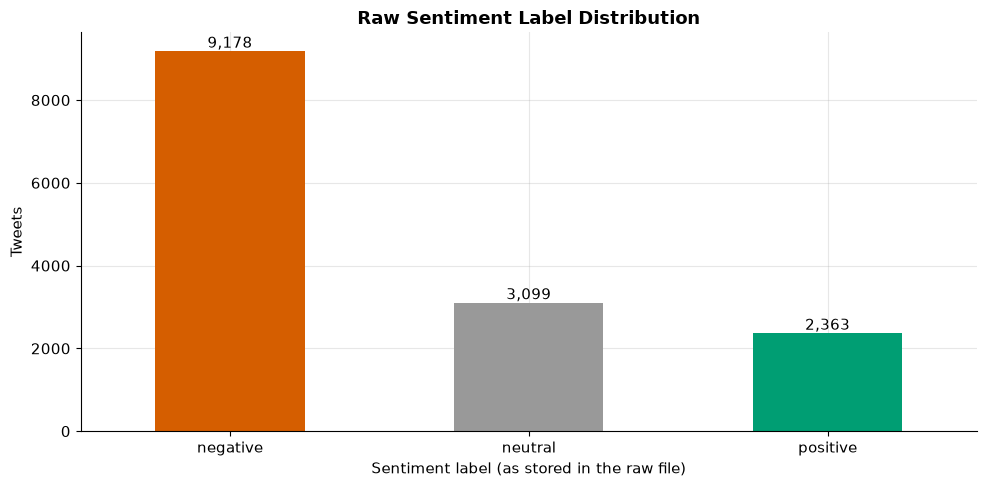

In [15]:
ax = sentiment_summary["tweet_count"].plot(
    kind="bar", color=[SENTIMENT_COLORS[label.title()] for label in sentiment_summary.index]
)
ax.set_title("Raw Sentiment Label Distribution")
ax.set_xlabel("Sentiment label (as stored in the raw file)")
ax.set_ylabel("Tweets")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
plt.tight_layout()
plt.show()

## 12. Airline Distribution

In [16]:
airline_counts = df["airline"].value_counts()

print(f"Number of unique airlines: {df['airline'].nunique()}")
print(f"Airlines: {', '.join(sorted(df['airline'].unique()))}")

airline_counts.to_frame("tweet_count")

Number of unique airlines: 6
Airlines: American, Delta, Southwest, US Airways, United, Virgin America


,tweet_count
airline,
United,3822
US Airways,2913
American,2759
Southwest,2420
Delta,2222
Virgin America,504


### 12.1 Airline Label Consistency Check

Customers normally tag the airline's official Twitter handle. If the `airline` label is reliable, each airline's tweets should mention that airline's handle. The check below uses a simple case-insensitive text match. It is a data-validation step, not text mining.

In [17]:
official_handles = {
    "Virgin America": "@virginamerica",
    "United": "@united",
    "Southwest": "@southwestair",
    "Delta": "@delta",
    "US Airways": "@usairways",
    "American": "@americanair",
}

lower_text = df["text"].str.lower()
handle_check = pd.DataFrame([
    {
        "airline": airline,
        "tweets": (df["airline"] == airline).sum(),
        "mention_own_handle": lower_text[df["airline"] == airline].str.contains(handle, regex=False).sum(),
        "mention_@jetblue": lower_text[df["airline"] == airline].str.contains("@jetblue", regex=False).sum(),
    }
    for airline, handle in official_handles.items()
])
handle_check["own_handle_pct"] = (handle_check["mention_own_handle"] / handle_check["tweets"] * 100).round(2)
handle_check

,airline,tweets,mention_own_handle,mention_@jetblue,own_handle_pct
0,Virgin America,504,504,1,100.00
1,United,3822,3822,4,100.00
2,Southwest,2420,2420,2,100.00
3,Delta,2222,6,2218,0.27
4,US Airways,2913,2913,2,100.00
5,American,2759,2759,7,100.00


In [18]:
# The few "Delta" rows that do not mention @JetBlue
delta_rows = df[df["airline"] == "Delta"]
for_display(delta_rows.loc[~delta_rows["text"].str.lower().str.contains("@jetblue", regex=False), ["tweet_id", "airline", "text"]])

,tweet_id,airline,text
7330,569667821455708160,Delta,"@user If you want, we can keep you updated on who's wearing who, &amp; who's with who, &amp; who wins what. We're ni..."
8215,568602015456215040,Delta,@user We think it's a treat to have you onboard! Enjoy your flight. 💙
12038,570294451261874177,Delta,@DeltaAssist now at 57 minutes waiting on Silver Elite line for someone to pick up! Help!
12039,568757671819661314,Delta,@DeltaAssist what I have to say is more than 140 characters! Plus you don't follow me


In [19]:
# Corroborating evidence: the "on fleek" exchange of February 2015 was a JetBlue social-media moment
fleek = delta_rows["text"].str.contains("fleek", case=False)
print(f"'Delta' rows mentioning 'fleek': {fleek.sum():,}")

'Delta' rows mentioning 'fleek': 150


**Important data-quality finding:** for five airlines, 100% of tweets mention the airline's own handle. For the rows labelled **Delta**, only 6 of 2,222 mention a Delta handle, while 2,218 are addressed to **@JetBlue**. Of the 4 rows that do not mention @JetBlue, 2 are addressed to @DeltaAssist and 2 are replies written by the airline itself with no airline handle. Around 150 of the rows react to JetBlue's well-known "on fleek" tweet.

The evidence shows that the source's `Delta` label is a labelling error for a JetBlue collection. Notebook 02 therefore applies a documented, rule-based correction (`src.data.correct_airline_labels`): rows labelled Delta that mention @JetBlue become **JetBlue**, and the original label is kept in an `airline_source` column. The raw file is not modified.

## 13. Negative Reason Analysis

Complaint categories as they appear in the raw file. Missing values are included so the structural gap is visible.

In [20]:
negative_reason_summary = (
    df["negativereason"]
    .value_counts(dropna=False)
    .rename_axis("negativereason")
    .to_frame("record_count")
)
negative_reason_summary["percentage_of_all_rows"] = (
    negative_reason_summary["record_count"] / len(df) * 100
).round(2)

negative_reason_summary

,record_count,percentage_of_all_rows
negativereason,,
NaN,5462,37.31
Customer Service Issue,2910,19.88
Late Flight,1665,11.37
Can't Tell,1190,8.13
Cancelled Flight,847,5.79
Lost Luggage,724,4.95
Bad Flight,580,3.96
Flight Booking Problems,529,3.61
Flight Attendant Complaints,481,3.29


Note: one category is stored as `longlines` while every other category is written in Title Case with spaces. The meaning is kept, and the label is standardised during cleaning.

## 14. Numerical Summary

In [21]:
# tweet_id is numeric in the raw file but is an identifier, so it is excluded
numeric_columns = ["airline_sentiment_confidence", "negativereason_confidence", "retweet_count"]
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
airline_sentiment_confidence,14640.0,0.900169,0.162830,0.335,0.6923,1.0000,1.0,1.0
negativereason_confidence,10522.0,0.638298,0.330440,0.000,0.3606,0.6706,1.0,1.0
retweet_count,14640.0,0.082650,0.745778,0.000,0.0000,0.0000,0.0,44.0


## 15. Retweet Count Statistics

In [22]:
retweets = df["retweet_count"]

print(f"Minimum retweets: {retweets.min():,}")
print(f"Maximum retweets: {retweets.max():,}")
print(f"Mean retweets: {retweets.mean():.4f}")
print(f"Median retweets: {retweets.median():.1f}")
print(f"Tweets with zero retweets: {(retweets == 0).sum():,} ({(retweets == 0).mean() * 100:.2f}%)")
print(f"Tweets with at least one retweet: {(retweets > 0).sum():,}")

Minimum retweets: 0
Maximum retweets: 44
Mean retweets: 0.0827
Median retweets: 0.0
Tweets with zero retweets: 13,873 (94.76%)
Tweets with at least one retweet: 767


## 16. Unique Value Analysis

In [23]:
df.nunique().sort_values(ascending=False).to_frame("unique_values")

,unique_values
tweet_id,14485
text,14427
tweet_created,14247
name,7701
tweet_location,3081
negativereason_confidence,1410
airline_sentiment_confidence,1023
tweet_coord,832
user_timezone,85
retweet_count,18


### 16.1 Timestamp Format Check

`tweet_created` is stored as text with a UTC offset suffix. We check which offsets occur and the time span covered. The parsing here is for inspection only, and `df` is not changed.

In [24]:
utc_offsets = df["tweet_created"].str[-5:].value_counts()
print("UTC offsets found in tweet_created:")
print(utc_offsets.to_string())

parsed_timestamps = pd.to_datetime(df["tweet_created"], errors="coerce", utc=True)
print(f"\nUnparseable timestamps: {parsed_timestamps.isna().sum():,}")
print(f"Earliest tweet (UTC): {parsed_timestamps.min()}")
print(f"Latest tweet (UTC):   {parsed_timestamps.max()}")
print(f"Collection window: {(parsed_timestamps.max() - parsed_timestamps.min()).days} days")

UTC offsets found in tweet_created:
tweet_created
-0800    14640



Unparseable timestamps: 0
Earliest tweet (UTC): 2015-02-17 07:36:05+00:00
Latest tweet (UTC):   2015-02-24 19:53:37+00:00
Collection window: 7 days


## 17. Initial Observations

The summary below is generated from the computed values above rather than typed in by hand.

In [25]:
missing_pct = df.isna().mean() * 100
top_sentiment = df["airline_sentiment"].value_counts(normalize=True)
top_reason = df["negativereason"].value_counts()

observations = [
    f"The raw dataset has {row_count:,} rows and {column_count} columns covering {df['airline'].nunique()} US airlines.",
    f"Three columns are almost empty: airline_sentiment_gold ({missing_pct['airline_sentiment_gold']:.2f}% missing), "
    f"negativereason_gold ({missing_pct['negativereason_gold']:.2f}%) and tweet_coord ({missing_pct['tweet_coord']:.2f}%).",
    f"negativereason is missing for {df['negativereason'].isna().sum():,} rows, and all of them are non-negative tweets, "
    f"so the gap is structural rather than a data error.",
    f"There are {exact_duplicate_count:,} exact duplicate rows and {df.duplicated('tweet_id').sum():,} extra rows that reuse a tweet_id; "
    f"{len(conflicting_sentiment_ids):,} tweet IDs carry conflicting sentiment labels.",
    f"The most common sentiment label is '{top_sentiment.idxmax()}' ({top_sentiment.max() * 100:.2f}% of rows).",
    f"The most discussed airline is {airline_counts.idxmax()} ({airline_counts.max():,} rows); the least is "
    f"{airline_counts.idxmin()} ({airline_counts.min():,} rows).",
    f"The most frequent complaint category is '{top_reason.idxmax()}' ({top_reason.max():,} rows).",
    f"Retweets are highly skewed: the median is {retweets.median():.0f} and the maximum is {retweets.max():,}.",
    f"Only {handle_check.set_index('airline').loc['Delta', 'own_handle_pct']:.2f}% of 'Delta' tweets mention @delta, while "
    f"{handle_check.set_index('airline').loc['Delta', 'mention_@jetblue']:,} mention @JetBlue: the Delta label looks unreliable.",
    f"All timestamps share a single UTC offset ({utc_offsets.index[0]}) and span only "
    f"{(parsed_timestamps.max() - parsed_timestamps.min()).days} days.",
]

for number, observation in enumerate(observations, start=1):
    print(f"{number}. {observation}")

1. The raw dataset has 14,640 rows and 15 columns covering 6 US airlines.
2. Three columns are almost empty: airline_sentiment_gold (99.73% missing), negativereason_gold (99.78%) and tweet_coord (93.04%).
3. negativereason is missing for 5,462 rows, and all of them are non-negative tweets, so the gap is structural rather than a data error.
4. There are 36 exact duplicate rows and 155 extra rows that reuse a tweet_id; 18 tweet IDs carry conflicting sentiment labels.
5. The most common sentiment label is 'negative' (62.69% of rows).
6. The most discussed airline is United (3,822 rows); the least is Virgin America (504 rows).
7. The most frequent complaint category is 'Customer Service Issue' (2,910 rows).
8. Retweets are highly skewed: the median is 0 and the maximum is 44.
9. Only 0.27% of 'Delta' tweets mention @delta, while 2,218 mention @JetBlue: the Delta label looks unreliable.
10. All timestamps share a single UTC offset (-0800) and span only 7 days.


### Implications for Cleaning (notebook 02)

1. Drop the near-empty `*_gold` and `tweet_coord` columns and the personally identifying `name` column.
2. Remove exact duplicate rows, then resolve the remaining repeated `tweet_id`s by keeping the highest-confidence record.
3. Fill structurally missing `negativereason` / `negativereason_confidence` and the optional profile fields rather than dropping rows.
4. Convert `tweet_id` to text and `tweet_created` to a proper datetime.
5. Standardise the category labels (`positive` → `Positive`, `longlines` → `Long Lines`).
6. Correct the `Delta` label to `JetBlue` where the tweet is addressed to @JetBlue, keep the source label in a separate column, and exclude the 4 rows whose airline cannot be verified.
7. Because the collection window is only about a week, time-based results should be read as descriptive of that window, not as long-term trends.